<a href="https://colab.research.google.com/github/rrohancodes/mini_project/blob/main/crowd_density.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [61]:
%cd /content/drive/MyDrive/crowd_project
from google.colab import files
files.upload()

/content/drive/MyDrive/crowd_project


Saving test.mp4 to test.mp4


{'test.mp4': b'\x00\x00\x00 ftypisom\x00\x00\x02\x00isomiso2avc1mp41\x00\x00\x00\x08free\x00e\xa5"mdat\x00\x03\x91R%\xb8@\x07_\xf3d\xb7\x95\xfa\x89\xdfm?\xb5_C\x84\xcb\xec2\xf2\\\x01\x84\x84\x1f\\\x83i\xfbW\xa4\xc0\x1e\xaf\xc5\xe1\xe4l\xc9/\x10\xc6"C\xea\x90\xc6\xa1\x85k\x8b(N\xf9\xadC\x8e\xed\xca\xdb7\xa1\xb0\x9b\x95$7H\xbf\xa4y\xe1\n\x10\xbf\x1e\xabwC\x9f\x1d\x1eUX/\x0cQCS0\rwc\xf1\xd3\x97u\x06\xfb>\xfaI\t\xd0\xb3\xed\x9f\x16\x8d\xd7\xeaH\x92Q\x1bC\x06\xbc\xc6w\xd9\xd7\xa0\x05\x13\xa5\x96"\xc1R\x1b\x9fr\xdb\xce\x15bQ \xab\xda\\\xd4\xf8\xe0\xf8\x9b&3T\\\xd6\xf8\xa8\x84(\x0f\xd1\xb0\xcfn\x0b\xf1\xc1K\xf0\x1b\xf5j\xe0\xd2\xb2\x88\x0c\x9a\xff!jI\x1b\x9a\xd7h\x81\x08\xb1\xc3\xc0\x04\x98\x18]\xea\xbfO\xa3\x80.T\x11\'~8\x85\x86\x87\\\xa9d\xf6\x1b9/\xe6=\xa2\xb9s\x9e\xc4a{\xcc\xf0^$\x9e\xac\x83LcN-\xbb\x80<R\x96\x91:\xd3]\x850\xef\xd4y\x18oqqBR\xe9\x04Dn\x8c\xb5\x99\x97\xdf\x8e\xd2\xa4W\xb0\xaf\x8f\xb1Z\xeb\xac\xda\x1a\x15\xa2\x9d\xd2>=\x96c:\xe7w\x87Q\x17\xd9\xff\xe1\xbf4\xd7\xe4\xd7Vp\xee\

In [62]:
%%writefile /content/drive/MyDrive/crowd_project/crowd_density.py
import argparse
import math
import time
from collections import defaultdict, deque

import cv2
import numpy as np

FONT = cv2.FONT_HERSHEY_SIMPLEX

LEVELS = [
    (0.33, "LOW", (0, 200, 0)),
    (0.66, "MEDIUM", (0, 215, 255)),
    (1.0, "HIGH", (0, 120, 255)),
    (float("inf"), "CRITICAL", (0, 0, 255)),
]


def risk_level(peak, sat):
    ratio = peak / sat
    for limit, name, color in LEVELS:
        if ratio < limit:
            return name, color


def people_risk_level(count, threshold):
    if count > threshold:
        return "CRITICAL", LEVELS[-1][2]
    ratio = count / threshold
    if ratio < 0.33:
        return "LOW", LEVELS[0][2]
    if ratio < 0.66:
        return "MEDIUM", LEVELS[1][2]
    return "HIGH", LEVELS[2][2]


def density_map(people, shape, alpha, scale=4):
    h, w = shape
    sh, sw = max(h // scale, 1), max(w // scale, 1)
    grid = np.zeros((sh, sw), np.float32)
    for cx, cy, bh in people:
        s = max(alpha * bh / scale, 1.0)
        r = int(3 * s)
        gx, gy = cx / scale, cy / scale
        x0, x1 = max(int(gx) - r, 0), min(int(gx) + r + 1, sw)
        y0, y1 = max(int(gy) - r, 0), min(int(gy) + r + 1, sh)
        if x0 >= x1 or y0 >= y1:
            continue
        xs = np.arange(x0, x1) - gx
        ys = np.arange(y0, y1) - gy
        grid[y0:y1, x0:x1] += np.exp(-(xs[None, :] ** 2 + ys[:, None] ** 2) / (2 * s * s))
    return cv2.resize(grid, (w, h), interpolation=cv2.INTER_LINEAR)


def overlay_heatmap(frame, density, sat, alpha=0.55):
    norm = np.clip(density / sat, 0, 1)
    color = cv2.applyColorMap((norm * 255).astype(np.uint8), cv2.COLORMAP_JET)
    blended = cv2.addWeighted(frame, 1 - alpha, color, alpha, 0)
    mask = (norm > 0.08)[..., None]
    return np.where(mask, blended, frame)


def draw_hud(frame, count, total, peak, average_speed, speed_unit, fps, sat, people_threshold, k):
    density_risk = risk_level(peak, sat)
    count_risk = people_risk_level(count, people_threshold)
    risk_order = {"LOW": 0, "MEDIUM": 1, "HIGH": 2, "CRITICAL": 3}
    overall_risk = max((density_risk, count_risk), key=lambda risk: risk_order[risk[0]])
    t = max(int(k), 1)
    cv2.rectangle(frame, (int(10 * k), int(10 * k)), (int(390 * k), int(220 * k)), (0, 0, 0), -1)
    cv2.rectangle(frame, (int(10 * k), int(10 * k)), (int(390 * k), int(220 * k)), overall_risk[1], t + 1)
    speed_text = f"{average_speed:.1f} {speed_unit}/s" if average_speed is not None else "N/A"
    lines = [
        (f"People now: {count}", (255, 255, 255)),
        (f"IDs created: {total}", (200, 200, 200)),
        (f"Peak density: {peak:.1f}", (200, 200, 200)),
        (f"Average speed: {speed_text}", (0, 255, 255)),
        (f"Density risk: {density_risk[0]}", density_risk[1]),
        (f"People risk: {count_risk[0]}", count_risk[1]),
        (f"Overall risk: {overall_risk[0]}", overall_risk[1]),
    ]
    y = 35
    for text, color in lines:
        cv2.putText(frame, text, (int(20 * k), int(y * k)), FONT, 0.5 * k, color, t)
        y += 25
    cv2.putText(frame, f"{fps:.1f} FPS", (frame.shape[1] - int(120 * k), int(28 * k)), FONT, 0.6 * k, (255, 255, 255), 2 * t)


def track_speed(trail, fps, gap=5):
    if len(trail) <= gap:
        return None
    p_now = trail[-1]
    p_old = trail[-1 - gap]
    d = math.dist(p_now, p_old)
    return d * fps / gap


def main():
    p = argparse.ArgumentParser()
    p.add_argument("--source", default="0")
    p.add_argument("--model", default="yolov8m.pt")
    p.add_argument("--out", default="crowd_output.mp4")
    p.add_argument("--conf", type=float, default=0.15)
    p.add_argument("--imgsz", type=int, default=1280)
    p.add_argument("--alpha", type=float, default=0.35)
    p.add_argument("--sat", type=float, default=4.0)
    p.add_argument("--people-threshold", type=int, default=20, help="people-count threshold for risk levels")
    p.add_argument("--trail", type=int, default=30)
    p.add_argument("--anchor", choices=["center", "foot"], default="center")
    p.add_argument("--speed-unit", choices=["bh", "px"], default="bh")
    p.add_argument("--trails", action="store_true")
    p.add_argument("--no-show", action="store_true")
    args = p.parse_args()
    if args.people_threshold <= 0:
        p.error("--people-threshold must be greater than zero")

    from ultralytics import YOLO

    model = YOLO(args.model)
    src = int(args.source) if args.source.isdigit() else args.source
    cap = cv2.VideoCapture(src)
    if not cap.isOpened():
        raise SystemExit(f"Cannot open source: {args.source}")

    w = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
    h = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
    src_fps = cap.get(cv2.CAP_PROP_FPS) or 25
    writer = cv2.VideoWriter(args.out, cv2.VideoWriter_fourcc(*"mp4v"), src_fps, (w, h))

    k = max(w / 960, 1.0)
    t = max(int(k), 1)
    history = defaultdict(lambda: deque(maxlen=args.trail))
    last_seen = {}
    seen_ids = set()
    frame_no = 0
    fps = 0.0

    while True:
        ok, frame = cap.read()
        if not ok:
            break
        t0 = time.time()
        frame_no += 1

        res = model.track(
            frame,
            persist=True,
            classes=[0],
            conf=args.conf,
            imgsz=args.imgsz,
            tracker="bytetrack.yaml",
            verbose=False,
        )[0]

        people, boxes_out = [], []
        boxes = res.boxes
        if boxes is not None and len(boxes):
            xyxy = boxes.xyxy.cpu().numpy()
            ids = boxes.id.int().cpu().tolist() if boxes.id is not None else [None] * len(xyxy)
            for (x1, y1, x2, y2), tid in zip(xyxy, ids):
                cx = (x1 + x2) / 2
                cy = y2 if args.anchor == "foot" else (y1 + y2) / 2
                people.append((cx, cy, y2 - y1))
                boxes_out.append((int(x1), int(y1), int(x2), int(y2), tid))
                if tid is not None:
                    history[tid].append((int(cx), int(cy)))
                    last_seen[tid] = frame_no
                    seen_ids.add(tid)

        for tid in [i for i, f in last_seen.items() if frame_no - f > 60]:
            history.pop(tid, None)
            last_seen.pop(tid, None)

        density = density_map(people, (h, w), args.alpha)
        peak = float(density.max()) if people else 0.0
        out = overlay_heatmap(frame, density, args.sat)

        speeds = []
        for x1, y1, x2, y2, tid in boxes_out:
            cv2.rectangle(out, (x1, y1), (x2, y2), (255, 255, 255), t)
            if tid is not None:
                speed = track_speed(history[tid], src_fps)
                if speed is not None:
                    if args.speed_unit == "bh":
                        speed /= max(y2 - y1, 1)
                    speeds.append(speed)

        average_speed = sum(speeds) / len(speeds) if speeds else None

        for trail in history.values() if args.trails else []:
            if len(trail) > 1:
                cv2.polylines(out, [np.array(trail, np.int32)], False, (255, 255, 0), t)

        dt = time.time() - t0
        fps = 0.9 * fps + 0.1 / dt if fps else 1 / dt
        draw_hud(out, len(people), len(seen_ids), peak, average_speed, args.speed_unit, fps, args.sat, args.people_threshold, k)

        writer.write(out)
        if not args.no_show:
            cv2.imshow("Crowd Density", out)
            if cv2.waitKey(1) & 0xFF == ord("q"):
                break

    cap.release()
    writer.release()
    cv2.destroyAllWindows()
    print(f"Saved: {args.out}")


if __name__ == "__main__":
    main()

Overwriting /content/drive/MyDrive/crowd_project/crowd_density.py


In [63]:
%cd /content/drive/MyDrive/crowd_project
!ls -la
!ls -la /content

/content/drive/MyDrive/crowd_project
total 135476
drwx------ 3 root root     4096 Oct 26 11:10 .
drwx------ 8 root root     4096 Oct 26 09:36 ..
-rw------- 1 root root  3936477 Oct 26 09:39 crowd20.mp4
-rw------- 1 root root  5234186 Oct 26 10:44 crowd2_20.mp4
-rw------- 1 root root  6678640 Oct 26 10:01 crowd2.mp4
-rw------- 1 root root     6622 Oct 26 11:10 crowd_density.py
-rw------- 1 root root  7152991 Oct 26 09:37 crowd.mp4
-rw------- 1 root root    64056 Oct 26 09:44 frame_1.jpg
-rw------- 1 root root    81431 Oct 26 09:44 frame_2.jpg
-rw------- 1 root root  9798812 Oct 26 10:45 out2.mp4
-rw------- 1 root root 19946558 Oct 26 10:49 out4.mp4
-rw------- 1 root root 19977898 Oct 26 10:58 out.mp4
drwx------ 2 root root     4096 Oct 26 10:20 __pycache__
-rw------- 1 root root   163154 Oct 26 11:00 shot_1.jpg
-rw------- 1 root root   152613 Oct 26 11:00 shot_2.jpg
-rw------- 1 root root   150682 Oct 26 11:00 shot_3.jpg
-rw------- 1 root root  6678640 Oct 26 11:10 test.mp4
-rw------- 1

In [64]:
%cd /content/drive/MyDrive/crowd_project
!pip install -q ultralytics lap
!python crowd_density.py --source test.mp4 --no-show --out out5.mp4
!ls -la out5.mp4

/content/drive/MyDrive/crowd_project
Saved: out5.mp4
-rw------- 1 root root 34146434 Oct 26 11:12 out5.mp4


/content/drive/MyDrive/crowd_project
total frames: 531 | fps: 25.0


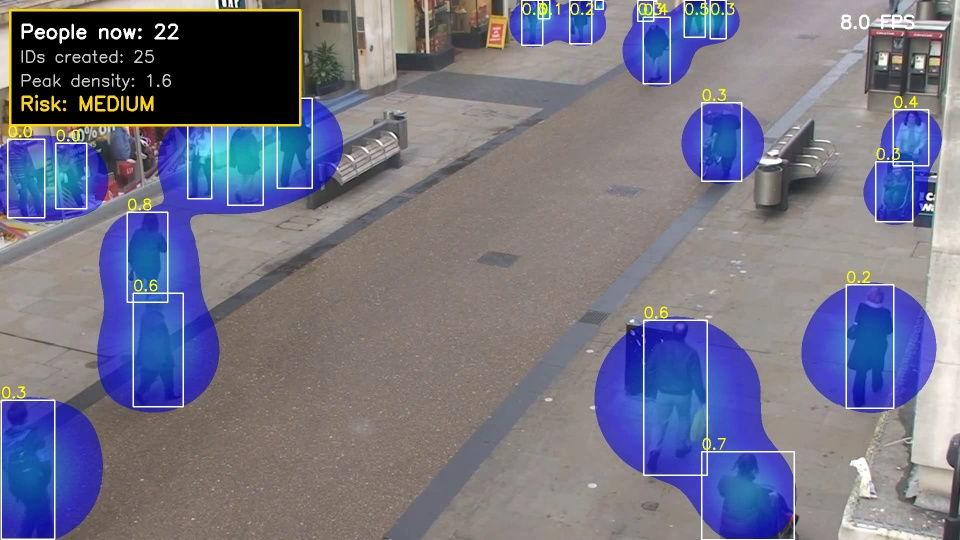

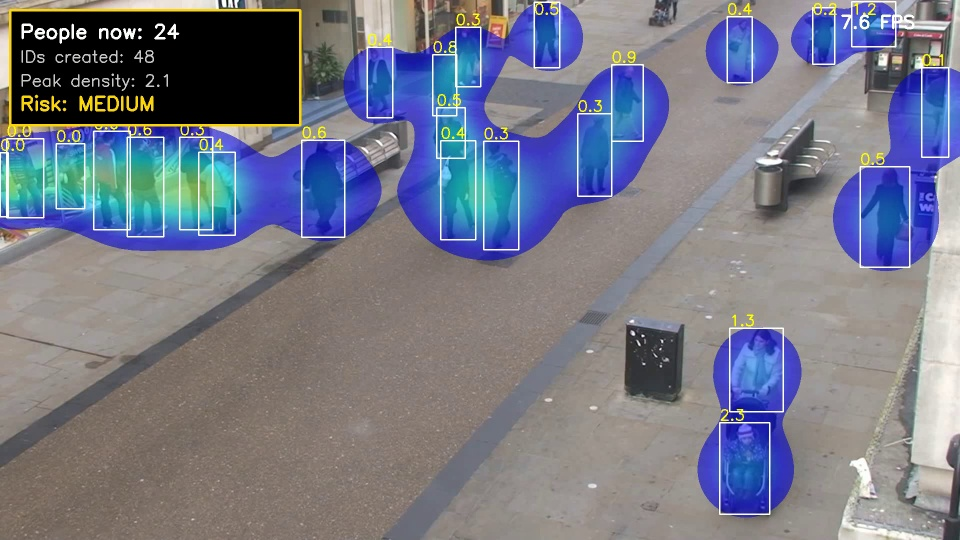

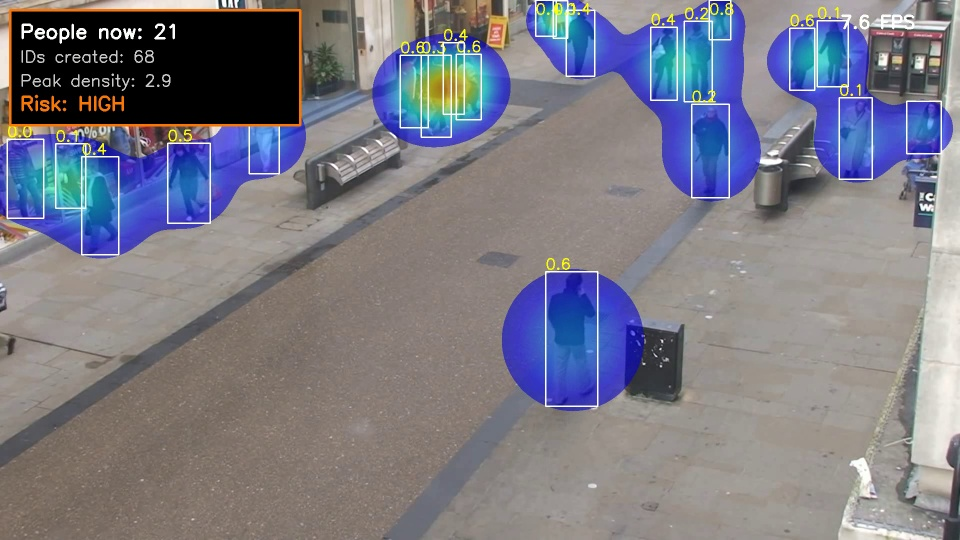

In [65]:
%cd /content/drive/MyDrive/crowd_project
import cv2
from IPython.display import Image, display

cap = cv2.VideoCapture('out5.mp4')
n = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
print("total frames:", n, "| fps:", cap.get(cv2.CAP_PROP_FPS))

for i, frac in enumerate((0.1, 0.5, 0.9), 1):
    cap.set(cv2.CAP_PROP_POS_FRAMES, int(n * frac))
    ok, frame = cap.read()
    if ok:
        frame = cv2.resize(frame, (960, int(frame.shape[0] * 960 / frame.shape[1])))
        cv2.imwrite(f'shot_{i}.jpg', frame)
        display(Image(f'shot_{i}.jpg'))
cap.release()

In [66]:
!python crowd_density.py --source test.mp4 --no-show --out out6.mp4 --sat 6

Saved: out6.mp4
